# Week 1: From text to tokens to vectors

**Introduction to LLMs** · about 60 minutes · runs on a free CPU (no GPU, no required downloads)

A language model never sees text the way you do. It sees **numbers**. In this notebook you build the path from one to the other:

```
 "a cat"   ──►   'a' ' ' 'c' 'a' 't'   ──►   5 1 7 5 21   ──►   5 rows of numbers
  text              tokens                  token IDs              vectors
        Part 1-3: the tokenizer                        Part 4: the embedding
```

**By the end you can**
1. explain what a token is, and why models don't simply use whole words or single letters;
2. write a small tokenizer that turns text into IDs and back;
3. say in one sentence what byte-pair encoding (BPE) adds;
4. turn token IDs into vectors, and say why we bother;
5. name a practical consequence of how text is cut.

### How this notebook works
- Run the cells from top to bottom (**Shift + Enter**).
- There are **five blanks**. Each is marked `# BLANK 1` to `# BLANK 5`: replace `None` with your own code. Most need one line.
- After each blank there is a check: ⬜ means not done yet, ❌ means look again (with a hint), ✅ means it works.
- The whole notebook also runs with the blanks empty, so you can read ahead.

**You need:** basic Python (lists, dictionaries, functions). No machine learning background.

**Setup.** Run this cell. You don't need to read it: it holds the automatic checks.

In [1]:
import torch
import matplotlib.pyplot as plt

STATUS = {}

def _report(name, problem):
    """problem is None (all good), 'todo' (the blank is empty), or a message."""
    STATUS[name] = "⬜" if problem == "todo" else "❌" if problem else "✅"
    if problem == "todo":
        print(f"⬜ {name}: not done yet. Replace None with your code, then run both cells again.")
    elif problem:
        print(f"❌ {name}: {problem}")
    else:
        print(f"✅ {name}: works!")
    return problem is None

def _safe(test, **hints):
    """Run a test. If the student's code raises an error, turn it into a readable hint."""
    try:
        return test()
    except Exception as err:
        kind = type(err).__name__
        return f"your code raised {kind}: {err}. " + hints.get(kind, "Read the message from the last line up.")

def check_vocab(fn):
    def test():
        v = fn("banana")
        if v is None: return "todo"
        if not isinstance(v, dict): return f"build_vocab should return a dictionary, but it returned: {type(v).__name__}."
        if not all(isinstance(k, str) for k in v): return "the keys should be characters and the values IDs. Yours look swapped."
        if not all(isinstance(i, int) for i in v.values()): return "the values should be numbers (the IDs). Did you leave a ____ in place?"
        if "<unk>" not in v: return "the special token '<unk>' is missing. Build the dictionary from `pieces`, which includes it."
        if len(v) != 4: return f"'banana' has 3 different characters plus <unk>, so expected 4 entries, got {len(v)}."
        if sorted(v.values()) != [0, 1, 2, 3]: return "the IDs should be 0, 1, 2, 3 with no gaps. enumerate() gives you exactly that."
        if v != {"<unk>": 0, "a": 1, "b": 2, "n": 3}: return "right size, wrong order: number the items of `pieces` in the order they come."
        if fn("ab") != {"<unk>": 0, "a": 1, "b": 2}: return "it works for 'banana' but not for 'ab'. Use the function's own text, not a fixed string."
    return _report("Blank 1 (build_vocab)", _safe(test, NameError="Every name on the left of 'for' must also appear right after 'for'."))

def check_encode(fn):
    def test():
        toy = {"<unk>": 0, "a": 1, "b": 2, "n": 3}
        out = fn("ban", toy)
        if out is None: return "todo"
        if not isinstance(out, list): return f"encode should return a list of IDs, but it returned: {type(out).__name__}. Use square brackets."
        if out != [2, 1, 3]: return f"encode('ban') should give [2, 1, 3], got {out}."
        if fn("bXn", toy) != [2, 0, 3]: return "an unknown character should become the ID of <unk>, which is 0 here. 'bXn' should give [2, 0, 3]."
        if fn("", toy) != []: return "empty text should give an empty list."
        if fn("aXb", {"<unk>": 5, "a": 7, "b": 9}) != [7, 5, 9]: return "it fails with another dictionary, where <unk> has ID 5. Use `stoi` and `unk_id`, not fixed numbers."
    return _report("Blank 2 (encode)", _safe(test, KeyError="That character isn't in the dictionary. Look it up with .get and a fallback."))

def check_decode(fn):
    def test():
        toy = {"<unk>": 0, "a": 1, "b": 2, "n": 3}
        out = fn([2, 1, 3], toy)
        if out is None: return "todo"
        if not isinstance(out, str): return f"decode should return a string, but it returned: {type(out).__name__}. Did you forget to join?"
        if out == "b a n": return "almost: there are extra spaces. Join with an empty string, \"\"."
        if out != "ban": return f"decode([2, 1, 3]) should give 'ban', got {out!r}."
        if fn([2, 0], toy) != "b<unk>": return "ID 0 should decode to '<unk>'."
    return _report("Blank 3 (decode)", _safe(test, KeyError="You have IDs, so look them up in itos, not stoi.",
                                             TypeError="join needs strings. Look up each ID in itos first."))

def check_table(fn):
    def test():
        out = fn(25, 8)
        if out is None: return "todo"
        if not isinstance(out, torch.nn.Embedding): return f"expected a torch.nn.Embedding, got: {type(out).__name__}. Did you add (rows, columns)?"
        got = tuple(out.weight.shape)
        if got == (8, 25): return "rows and columns are swapped. We want one ROW per token: (25, 8), got (8, 25)."
        if got != (25, 8): return f"with vocab_size=25 and dim=8 the table should have shape (25, 8), got {got}."
        if tuple(fn(5, 3).weight.shape) != (5, 3): return "use vocab_size and dim, not fixed numbers."
    return _report("Blank 4 (embedding table)", _safe(test, TypeError="It needs two numbers: rows, then columns."))

def check_lookup(fn):
    def test():
        toy = torch.nn.Embedding(6, 4)
        out = fn([5, 2, 2], toy)
        if out is None: return "todo"
        if not isinstance(out, torch.Tensor): return f"expected a tensor, got: {type(out).__name__}."
        if tuple(out.shape) != (3, 4): return f"three IDs and embedding size 4 should give shape (3, 4), got {tuple(out.shape)}."
        for position, token_id in enumerate([5, 2, 2]):
            if out[position].tolist() != toy.weight[token_id].tolist():
                return f"position {position} should hold row {token_id} of the table, but it doesn't."
    return _report("Blank 5 (look up)", _safe(test, TypeError="The table wants a tensor, not a Python list. Wrap the IDs first.",
                                              AttributeError="The table wants a tensor, not a Python list. Wrap the IDs first."))

print("Ready. PyTorch", torch.__version__)

Ready. PyTorch 2.5.1


## Predict first (1 minute)

Before any code, write down your guesses. Being wrong here is useful.

1. How many pieces does GPT-2 (OpenAI's 2019 model, which we use as our example) cut `unbelievable` into, when it stands at the very start of a text? **Your guess:**
2. And how many for the number `12345678`? **Your guess:**

You'll find the answers in Part 3.

---
## Part 1 · Two obvious ways to cut text

A **token** is one piece of text. **Tokenizing** means cutting text into pieces. The two obvious choices are *words* and *characters*. Let's try both. (`set(...)` below keeps one copy of each item, so its length counts the *different* pieces.)

In [2]:
text = ("The little boat left the dock at sunrise. "
        "The wind was light and the water was calm. "
        "By noon the boat was far from the dock.")

words = text.split()      # cut at spaces
chars = list(text)        # cut everywhere

print("words:     ", words[:8], "...")
print("characters:", chars[:8], "...")
print()
print(f"{len(words):4d} word pieces,      {len(set(words)):3d} different ones")
print(f"{len(chars):4d} character pieces, {len(set(chars)):3d} different ones")

words:      ['The', 'little', 'boat', 'left', 'the', 'dock', 'at', 'sunrise.'] ...
characters: ['T', 'h', 'e', ' ', 'l', 'i', 't', 't'] ...

  26 word pieces,       19 different ones
 124 character pieces,  24 different ones


The list of all the different pieces a model knows is its **vocabulary**. Now read a sentence that uses a word we haven't seen:

In [3]:
new_text = "The kayak left the dock."
known_words, known_chars = set(words), set(chars)

print("unknown words:     ", [w for w in new_text.split() if w not in known_words])
print("unknown characters:", [c for c in new_text if c not in known_chars])

unknown words:      ['kayak']
unknown characters: []


| Cut into | Pieces per sentence | Vocabulary | Never-seen words |
|---|---|---|---|
| **Words** | few ✓ | huge, and never complete | no ID at all ✗ |
| **Characters** | many ✗ (slow, little meaning each) | small for one alphabet ✓ | usually fine ✓ |

(Notice `dock.` with its full stop counts as a different "word" from `dock`. Cutting at spaces is cruder than it looks.)

Real models use something **in between**. You'll see it in Part 3. First, build the simplest tokenizer that works.

---
## Part 2 · Main exercise: build a tokenizer

You need three things: a **vocabulary** (piece → ID), **encode** (text → IDs) and **decode** (IDs → text).

### Blank 1 · The vocabulary

Give every different character its own number. We keep ID **0** for a special token, `<unk>`, which stands for "a character I have never seen".

Three pieces of Python you need, shown on a *different* example:

In [4]:
fruits = ["apple", "kiwi", "plum"]

print(list(enumerate(fruits)))                          # enumerate numbers the items
print({name: len(name) for name in fruits})             # a dictionary built in one line
print([name.upper() for name in fruits])                # a list built in one line

[(0, 'apple'), (1, 'kiwi'), (2, 'plum')]
{'apple': 5, 'kiwi': 4, 'plum': 4}
['APPLE', 'KIWI', 'PLUM']


> **Common surprise:** `print(enumerate(fruits))` shows something like `<enumerate object at 0x...>`, not the pairs. `enumerate` waits until something loops over it. Wrap it in `list(...)` to see inside.

In [5]:
def build_vocab(text):
    """Return a dictionary {piece: ID}, with '<unk>' as ID 0."""
    pieces = ["<unk>"] + sorted(set(text))   # e.g. "banana" -> ['<unk>', 'a', 'b', 'n']

    # BLANK 1: a dictionary that maps each piece to its position in the list
    # Shape of the answer:  {____ : ____ for ____, ____ in enumerate(pieces)}
    stoi = None

    return stoi

<details><summary>Hint for Blank 1</summary>

`enumerate(pieces)` gives pairs `(number, piece)`, with the number first. The dictionary needs the *piece* as the key and the *number* as the value. (The name `stoi` is short for "string to integer".)

</details>

In [6]:
ok1 = check_vocab(build_vocab)

⬜ Blank 1 (build_vocab): not done yet. Replace None with your code, then run both cells again.


### Blank 2 · Encode

Go through the text one character at a time and look up each ID. If a character isn't in the dictionary, use the ID of `<unk>`.

Useful Python, again on a different example: `.get` looks something up with a fallback.

In [7]:
prices = {"apple": 2, "kiwi": 1}
print(prices.get("kiwi", 99))     # found
print(prices.get("mango", 99))    # not found, so the fallback

1
99


In [8]:
def encode(text, stoi):
    """Text -> list of IDs."""
    unk_id = stoi["<unk>"]

    # BLANK 2: a list with one ID per character of text; unknown characters become unk_id
    # Shape of the answer:  [____ for ch in text]
    ids = None

    return ids

<details><summary>Hint for Blank 2</summary>

Inside the square brackets you need one lookup in `stoi` for `ch`, with `unk_id` as the fallback.

</details>

In [9]:
ok2 = check_encode(encode)

⬜ Blank 2 (encode): not done yet. Replace None with your code, then run both cells again.


### Blank 3 · Decode

Turn the dictionary around (ID → piece; that line is done for you), look up every ID, and glue the pieces together.

In [10]:
def decode(ids, stoi):
    """List of IDs -> text."""
    itos = {i: piece for piece, i in stoi.items()}   # integer -> string

    # BLANK 3: look up every ID in itos and join the pieces into one string
    # Reminder:  "-".join(["x", "y"])  gives  "x-y"
    # Shape of the answer:  "".join([____ for i in ids])
    out = None

    return out

<details><summary>Hint for Blank 3</summary>

First turn every ID into its piece, with a list built in one line: look up `i` in `itos`. Then join that list with the *empty* string, `""`. (Spaces are already characters of their own.)

</details>

In [11]:
ok3 = check_decode(decode)

⬜ Blank 3 (decode): not done yet. Replace None with your code, then run both cells again.


### Put it together: the round trip

A tokenizer is correct when decoding what you encoded gives back **exactly** the same text, as long as every character is in the vocabulary.

In [12]:
tokenizer_ready = ok1 and ok2 and ok3
if tokenizer_ready:
    stoi = build_vocab(text)
    ids = encode("a cat", stoi)
    print("vocabulary size:", len(stoi))
    print("'a cat' ->", ids, "->", repr(decode(ids, stoi)))
    print("round trip on the whole text:", decode(encode(text, stoi), stoi) == text)
    print()
    print("a word we never saw:     ", repr(decode(encode("kayak", stoi), stoi)))
    print("a character we never saw:", repr(decode(encode("café", stoi), stoi)))
else:
    print("⬜ Finish Blanks 1 to 3 (and run their checks), then run this cell.")

⬜ Finish Blanks 1 to 3 (and run their checks), then run this cell.


**Look at the last two lines.** The unseen *word* survives, because all of its letters are known. The unseen *character* is lost: it becomes `<unk>` and cannot be recovered. Keep that in mind for Part 3.

*Your words, one sentence:* why does `kayak` work and `café` not?

---
## Part 3 · The middle way: byte-pair encoding (BPE)

Words are too many. Characters are too small. **BPE** learns pieces of *in-between* size from data:

1. Start with the smallest pieces.
2. Find the two neighbouring pieces that appear together most often.
3. Glue them into one new piece, and add it to the vocabulary.
4. Repeat until the vocabulary is as big as you want.

One round, on a tiny text (a space is shown as `␣`):

```
 t h e ␣ c a t ␣ s a t ␣ o n ␣ t h e ␣ m a t        22 pieces
           └┬┘     └┬┘                   └┬┘
 most common pair: a + t   (3 times)   ->  new piece "at"

 t h e ␣ c at ␣ s at ␣ o n ␣ t h e ␣ m at           19 pieces, vocabulary +1
```

Each round is called a **merge**. Common chunks end up as a single piece. Rare words are spelled from smaller pieces, so almost nothing is ever unknown. (Simplified: real tokenizers usually split the text into word-like chunks first, and only count neighbours inside a chunk.)

Sennrich, Haddow and Birch brought this idea to machine translation in 2016, starting from **characters**. GPT-2 starts from **bytes**. A byte is the unit computers store text in, and there are only 256 different ones, so *no text at all* is unknown to it, not even `é` or an emoji.

> **Exercise 1B · The BPE merge loop** is a separate notebook in this week's module.
>
> There you write the loop above yourself, with automatic checks. Nothing later in *this* notebook depends on it.

### What a real tokenizer does

GPT-2's vocabulary has **50,257** pieces: 256 bytes, 50,000 learned merges, and one end-of-text marker. (There is no `<unk>`: it doesn't need one.) The results below were recorded from GPT-2's own tokenizer (OpenAI's `tiktoken` library, encoding `gpt2`), so nothing is downloaded. The space in front of a word is shown as `␣`.

In [13]:
# Recorded with tiktoken 0.14.0, encoding "gpt2": text -> list of (ID, piece)
GPT2 = {
    "cat":          [(9246, "cat")],
    " cat":         [(3797, " cat")],
    "strawberry":   [(301, "st"), (1831, "raw"), (8396, "berry")],
    " strawberry":  [(41236, " strawberry")],
    "tokenization": [(30001, "token"), (1634, "ization")],
    "unbelievable": [(403, "un"), (6667, "bel"), (11203, "iev"), (540, "able")],
    " unbelievable": [(24479, " unbelievable")],
    "Zyntharil":    [(57, "Z"), (2047, "yn"), (400, "th"), (283, "ar"), (346, "il")],   # a made-up name
    "12345678":     [(10163, "123"), (2231, "45"), (30924, "678")],
    "hello world":  [(31373, "hello"), (995, " world")],
    "hola mundo":   [(3937, "hol"), (64, "a"), (27943, " mund"), (78, "o")],
}

for word, pieces in GPT2.items():
    shown = " | ".join(p.replace(" ", "␣") for _, p in pieces)
    name = word.replace(" ", "␣")
    count = f"{len(pieces)} piece" + ("s" if len(pieces) > 1 else "")
    print(f"{name:13} {len(word):2d} characters -> {count:8}  {shown:25}  IDs {[i for i, _ in pieces]}")

cat            3 characters -> 1 piece   cat                        IDs [9246]
␣cat           4 characters -> 1 piece   ␣cat                       IDs [3797]
strawberry    10 characters -> 3 pieces  st | raw | berry           IDs [301, 1831, 8396]
␣strawberry   11 characters -> 1 piece   ␣strawberry                IDs [41236]
tokenization  12 characters -> 2 pieces  token | ization            IDs [30001, 1634]
unbelievable  12 characters -> 4 pieces  un | bel | iev | able      IDs [403, 6667, 11203, 540]
␣unbelievable 13 characters -> 1 piece   ␣unbelievable              IDs [24479]
Zyntharil      9 characters -> 5 pieces  Z | yn | th | ar | il      IDs [57, 2047, 400, 283, 346]
12345678       8 characters -> 3 pieces  123 | 45 | 678             IDs [10163, 2231, 30924]
hello␣world   11 characters -> 2 pieces  hello | ␣world             IDs [31373, 995]
hola␣mundo    10 characters -> 4 pieces  hol | a | ␣mund | o        IDs [3937, 64, 27943, 78]


Check your predictions, then answer in one line each:

1. At the start of a text, `strawberry` is three pieces. Inside a sentence, `␣strawberry` is a *single* piece, ID 41236. Either way the model isn't given letters. Why might "how many r's are in strawberry?" be an awkward question for it?
2. `cat` and `␣cat` have different IDs. Where does GPT-2 keep the space?
3. `Zyntharil` is made up, so it can't have been learned as one piece. What happened instead of `<unk>`?
4. How is `12345678` cut? Would you cut it there if you wanted to do arithmetic?
5. Suppose a service charges per token. `hello world` and `hola mundo` say the same thing: which costs more here, and what does that suggest about the text GPT-2's tokenizer learned from?

> **Tokenizers are not neutral.** Petrov et al. (2023) took the same sentences, translated into 200 languages, and counted tokens. Compared with English, the most affected language needed about 15 times as many with the ChatGPT/GPT-4 tokenizer, and almost 19 times as many with GPT-2's. More tokens means slower, more expensive, and less text that fits into the model at once.

*(Optional, uses the network once: set the switch below to `True` to try your own words.)*

In [14]:
TRY_MY_OWN_WORDS = False      # True downloads GPT-2's vocabulary (about 1.5 MB) the first time
my_words = ["Pensacola", "antidisestablishmentarianism"]

if TRY_MY_OWN_WORDS:
    try:
        import tiktoken       # if missing: run  %pip install tiktoken  in a new cell
        gpt2 = tiktoken.get_encoding("gpt2")
        for w in my_words:
            token_ids = gpt2.encode(w)
            print(repr(w), "->", token_ids, [gpt2.decode([i]) for i in token_ids])
    except Exception as err:
        print("Could not load tiktoken:", err)
else:
    print("Skipped (TRY_MY_OWN_WORDS is False).")

Skipped (TRY_MY_OWN_WORDS is False).


---
## Part 4 · From IDs to vectors

Now each piece has an ID. But an ID is a **label, not an amount**. GPT-2 gives `␣dog` the ID 3290 and `␣cat` the ID 3797. That doesn't make a cat "507 more" than a dog. If we fed raw IDs to the model as numbers, it would believe something like that.

So each ID picks its own **row of numbers** from a table. That row is the token's **embedding**, also called its **vector**.

```
 token ID            embedding table (one row per token in the vocabulary)

             row 0   [  0.3  -0.2   0.9   0.1 ]
             row 1   [ -0.7   0.6   0.2  -0.4 ]
             row 2   [  0.5   1.1  -0.3   0.0 ]
    3  ───►  row 3   [ -1.1   0.4   0.0   0.7 ]   ◄── the vector for token 3
             row 4   [  0.8  -0.5   0.2  -0.9 ]
                        └─── embedding size ──┘
```

The numbers start **random** and are adjusted during **training**, when the model practises predicting text and its numbers are nudged a little after every mistake (Week 4). After training, tokens used in similar ways tend to end up with similar rows.

### Predict the shape

Your vocabulary has 25 tokens and we choose an embedding size of 8. How many rows does the table have? How many columns? **Your prediction:**

### Blank 4 · Make the table

PyTorch has a ready-made table filled with random numbers. Here is one with 4 rows and 2 columns, and how to look rows up. PyTorch wants the IDs as a **tensor**, its own kind of array:

In [15]:
torch.manual_seed(0)
toy_table = torch.nn.Embedding(4, 2)      # 4 tokens, 2 numbers each
wanted = torch.tensor([3, 1])             # a tensor with two IDs

print(toy_table.weight.detach())          # the whole table (.detach() only tidies the printout)
print(toy_table(wanted).detach())         # rows 3 and 1

tensor([[ 1.5410, -0.2934],
        [-2.1788,  0.5684],
        [-1.0845, -1.3986],
        [ 0.4033,  0.8380]])
tensor([[ 0.4033,  0.8380],
        [-2.1788,  0.5684]])


In [16]:
def make_table(vocab_size, dim):
    # BLANK 4: one row per token, dim numbers in each row
    table = None
    return table

<details><summary>Hint for Blank 4</summary>

Same call as `toy_table`, with the function's own two numbers. Rows come first, and there is one **row** per token.

</details>

In [17]:
ok4 = check_table(make_table)

⬜ Blank 4 (embedding table): not done yet. Replace None with your code, then run both cells again.


### Blank 5 · Look up some vectors

Given a Python **list** of IDs and a table, return the matching rows. Before you run the check: if you pass 3 IDs and the embedding size is 4, what shape comes out?

In [18]:
def lookup(ids, table):
    # BLANK 5: ids is a plain list, and the table wants a tensor
    vectors = None
    return vectors

<details><summary>Hint for Blank 5</summary>

Two steps, as in the `toy_table` example: make a tensor from `ids`, then call the table on it, the way you call a function.

</details>

In [19]:
ok5 = check_lookup(lookup)

⬜ Blank 5 (look up): not done yet. Replace None with your code, then run both cells again.


### The whole path

Text → tokens → IDs → vectors, with your own code at every step:

In [20]:
if tokenizer_ready and ok4 and ok5:
    torch.manual_seed(123)                       # so everyone gets the same random numbers
    stoi = build_vocab(text)
    table = make_table(len(stoi), 8)             # 25 tokens, embedding size 8
    ids = encode("boat", stoi)
    vectors = lookup(ids, table)
    print("'boat' ->", ids)
    print("table:  ", tuple(table.weight.shape), "= (tokens in the vocabulary, embedding size)")
    print("vectors:", tuple(vectors.shape), "  = (tokens in 'boat', embedding size)")
    print(vectors.detach())
else:
    print("⬜ Finish Blanks 1 to 5 (and run their checks), then run this cell.")

⬜ Finish Blanks 1 to 5 (and run their checks), then run this cell.


### Why bother? A map of meaning

With 2 numbers per token, we can draw the vectors as points. The positions below are **placed by hand to show the idea**. They are not from a trained model.

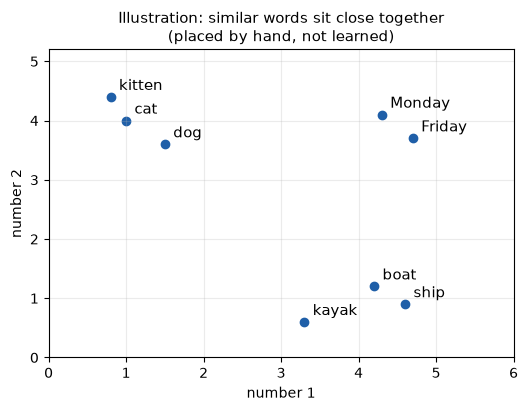

In [21]:
by_hand = {"cat": (1.0, 4.0), "dog": (1.5, 3.6), "kitten": (0.8, 4.4),
           "boat": (4.2, 1.2), "ship": (4.6, 0.9), "kayak": (3.3, 0.6),
           "Monday": (4.3, 4.1), "Friday": (4.7, 3.7)}

fig, ax = plt.subplots(figsize=(6, 4))
for word, (x, y) in by_hand.items():
    ax.scatter(x, y, color="#1f5fa8")
    ax.annotate(word, (x, y), textcoords="offset points", xytext=(6, 5), fontsize=11)
ax.set_xlim(0, 6); ax.set_ylim(0, 5.2)
ax.set_xlabel("number 1"); ax.set_ylabel("number 2")
ax.set_title("Illustration: similar words sit close together\n(placed by hand, not learned)", fontsize=11)
ax.grid(alpha=0.25)
plt.show()

Real models use hundreds or thousands of numbers per token. The smallest GPT-2 uses 768, so its table holds 50,257 × 768 = **38,597,376** numbers before the model does anything else. That is one price of a big vocabulary.

**What's still missing?** The vectors for `boat` don't know they are in the order b-o-a-t. The model also needs to know *where* each token is. That comes with the GPT block in Week 3.

---
## Wrap-up

Run this to see where you stand:

In [22]:
for name, mark in STATUS.items():
    print(mark, name)

⬜ Blank 1 (build_vocab)
⬜ Blank 2 (encode)
⬜ Blank 3 (decode)
⬜ Blank 4 (embedding table)
⬜ Blank 5 (look up)


### Say it in your own words (one or two sentences each)

1. What is a token? Why not use whole words?
2. What does BPE add, compared with your character tokenizer?
3. A bigger vocabulary: one thing you gain, one thing you pay.
4. Why does each ID get a vector instead of being used as a number?

<details><summary>Sample answers (write yours first)</summary>

1. A token is a piece of text with a number. The list of whole words never ends, and a word that isn't on it has no number.
2. BPE learns longer pieces from how often they occur, so texts become shorter lists, and rare words can still be spelled from parts.
3. Gain: fewer pieces per text. Pay: a bigger table of vectors, and rare pieces the model hardly ever sees.
4. The number is only a label, so arithmetic on it means nothing. A vector gives training something to adjust for each token.

</details>

### Going further (optional)
- Andrej Karpathy, *Let's build the GPT Tokenizer* (video): https://www.youtube.com/watch?v=zduSFxRajkE. **Also walks through the full answer to Exercise 1B.**
- Sebastian Raschka, *Implementing A Byte Pair Encoding (BPE) Tokenizer From Scratch* (2025): https://sebastianraschka.com/blog/2025/bpe-from-scratch.html. **Contains the full answer to Exercise 1B**, so try that first.
- Play with real tokenizers in the browser: https://tiktokenizer.vercel.app/

### Sources and credits
- R. Sennrich, B. Haddow, A. Birch (2016). *Neural Machine Translation of Rare Words with Subword Units.* ACL 2016, pp. 1715–1725. https://aclanthology.org/P16-1162/ (CC BY 4.0)
- P. Gage (1994). *A New Algorithm for Data Compression.* The C Users Journal 12(2), 23–38. The original byte-pair idea.
- A. Radford et al. (2019). *Language Models are Unsupervised Multitask Learners* (GPT-2). Byte-level BPE, 50,257 tokens.
- A. Petrov, E. La Malfa, P. H. S. Torr, A. Bibi (2023). *Language Model Tokenizers Introduce Unfairness Between Languages.* NeurIPS 2023. https://arxiv.org/abs/2305.15425
- Course order inspired by S. Raschka, *Build a Large Language Model (From Scratch)*, Manning, 2024, ch. 2, and A. Karpathy's tokenizer lecture. The text, code, exercise and drawings here were written for this course; no code, figures or book text were copied. Their code is available under Apache 2.0 (Raschka, https://github.com/rasbt/LLMs-from-scratch) and MIT (Karpathy, https://github.com/karpathy/minbpe).
- GPT-2 tokenizations recorded with OpenAI `tiktoken` (MIT license).